Link to dataset: https://www.kaggle.com/datasets/vedauv/what-makes-a-movie-a-blockbuster-5000-films?select=movie_blockbusters.csv

Step 1:

**Problem Statement** - What Makes a Movie a Blockbuster?

**Dataset Description** - The “What Makes a Movie a Blockbuster?” dataset, published on Kaggle by a user named Ved, contains synthetic data on 5,000 artificial films. The dataset includes information about each movie, including its title, release year, release decade, genre, runtime (minutes), budget, revenue, profit, ROI, rating, vote count, popularity, and blockbuster status.

**Target Variable Analysis** - The target variable of this dataset is “blockbuster,” which represents whether a movie was deemed popular or financially successful. In this dataset, 0 represents movies that are not blockbusters, while 1 represents movies that are blockbusters. The initial dataset contains 673 blockbuster movies and 4,327 non-blockbuster movies.

**Prediction Goal** - The goal of this model is to successfully predict whether a movie is labeled a blockbuster or not a blockbuster. The model will not use revenue, profit, roi, rating, vote count, or popularity in the prediction model because they would contribute to data leakage, which would heavily influence its accuracy.

In [2]:
#Import python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SelectKBest, f_classif, chi2
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

#Mount google drive to the file
from google.colab import drive
drive.mount('/content/drive')

#Import database
df = pd.read_csv('/content/drive/MyDrive/movie_blockbusters.csv')

#Intial Shape of the Database
print("Initial Shape: ", df.shape)

Mounted at /content/drive
Initial Shape:  (5000, 14)


In [3]:
#Prints total values of the target variable
print('Target Variable Distribution')
print(df['blockbuster'].value_counts())

#Prints the perecentages of the target variable
print('\nTarget Variable Percentages')
print((df['blockbuster'].value_counts(normalize=True).sort_index()*100).round(2))

Target Variable Distribution
blockbuster
0    4327
1     673
Name: count, dtype: int64

Target Variable Percentages
blockbuster
0    86.54
1    13.46
Name: proportion, dtype: float64


Step 2: Basic Data Cleaning

A.) Drop Unwanted Features

The columns 'movie_id', 'title', and 'decade' are not used as prediction features, and 'revenue_usd', 'profit_usd', 'roi', 'rating', 'vote_count', and 'popularity' are only available after release.

In [4]:
#Drop unwanted features
df = df.drop(columns=[
    'movie_id',
    'title',
    'decade',
    'revenue_usd',
    'profit_usd',
    'roi',
    'rating',
    'vote_count',
    'popularity'
    ])

#Displays the remaining columns
print("Remaining Columns:")
print(df.columns.tolist())

Remaining Columns:
['year', 'genre', 'runtime_min', 'budget_usd', 'blockbuster']


B.) Check for missing values

There are no missing values that need to be addressed.

In [5]:
#Prints the number of missing values
print("Missing Values: ")
print(df.isnull().sum())

Missing Values: 
year           0
genre          0
runtime_min    0
budget_usd     0
blockbuster    0
dtype: int64


C.) Check for duplicates

There are no duplicate values that need to be addressed.

In [6]:
#Checks for duplicate values
print("Number of Duplicates: ", df.duplicated().sum())

Number of Duplicates:  0


D.) Check and address inconsistent inputs for categorical variables

All categorical variable are consistent.

In [7]:
#Removes spaces and implicates standardized capitalization
df['genre'] = df['genre'].str.strip().str.title()

#Prints genre values
print("Unique genres:")
print(sorted(df['genre'].unique()), '\n')

print("Genre Counts:")
print(df['genre'].value_counts())

Unique genres:
['Action', 'Adventure', 'Animation', 'Comedy', 'Documentary', 'Drama', 'Horror', 'Romance', 'Sci-Fi', 'Thriller'] 

Genre Counts:
genre
Documentary    544
Animation      522
Adventure      515
Drama          507
Thriller       499
Comedy         499
Action         488
Sci-Fi         478
Horror         477
Romance        471
Name: count, dtype: int64


E.) Use boxplots or histograms to identify outliers for numeric variables and remove them


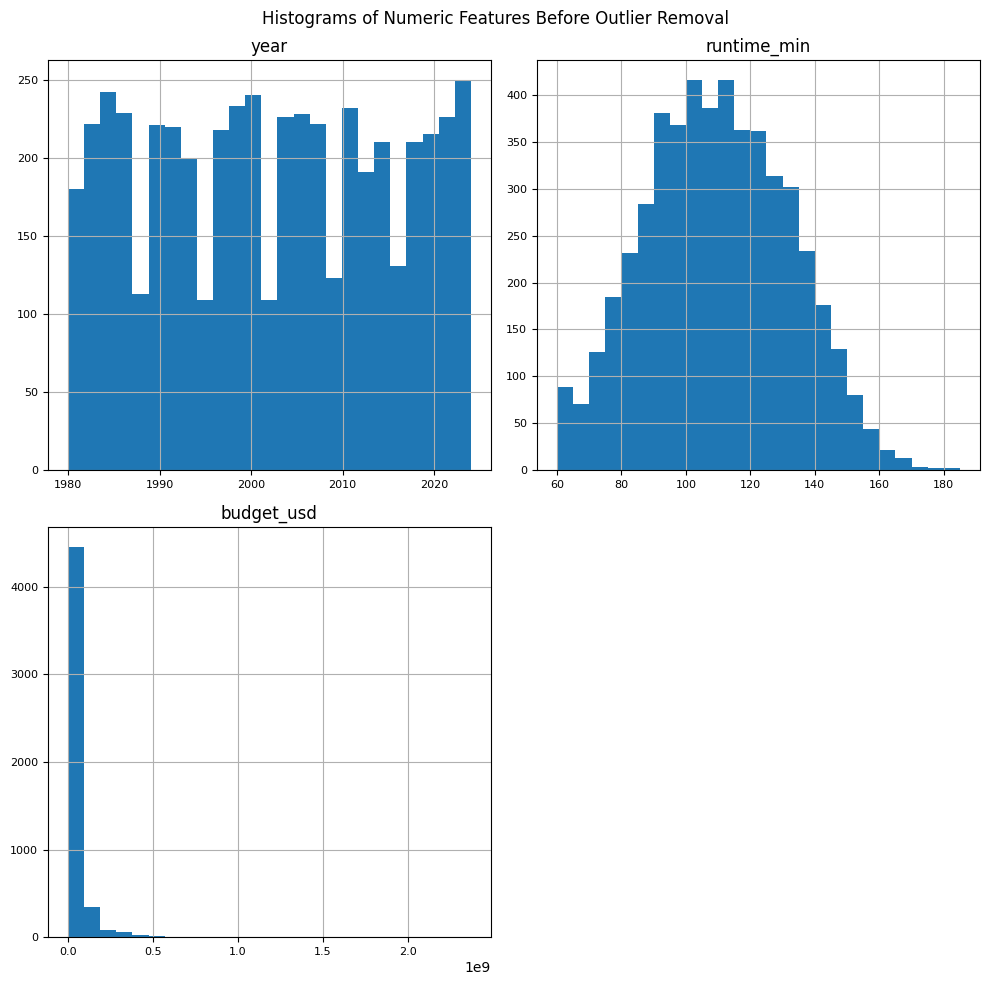

In [8]:
#Plots histograms before outlier removal
num_cols = ['year', 'runtime_min', 'budget_usd']
df[num_cols].hist(figsize=(10, 10), bins=25, xlabelsize=8, ylabelsize=8)
plt.suptitle('Histograms of Numeric Features Before Outlier Removal')
plt.tight_layout()
plt.show()

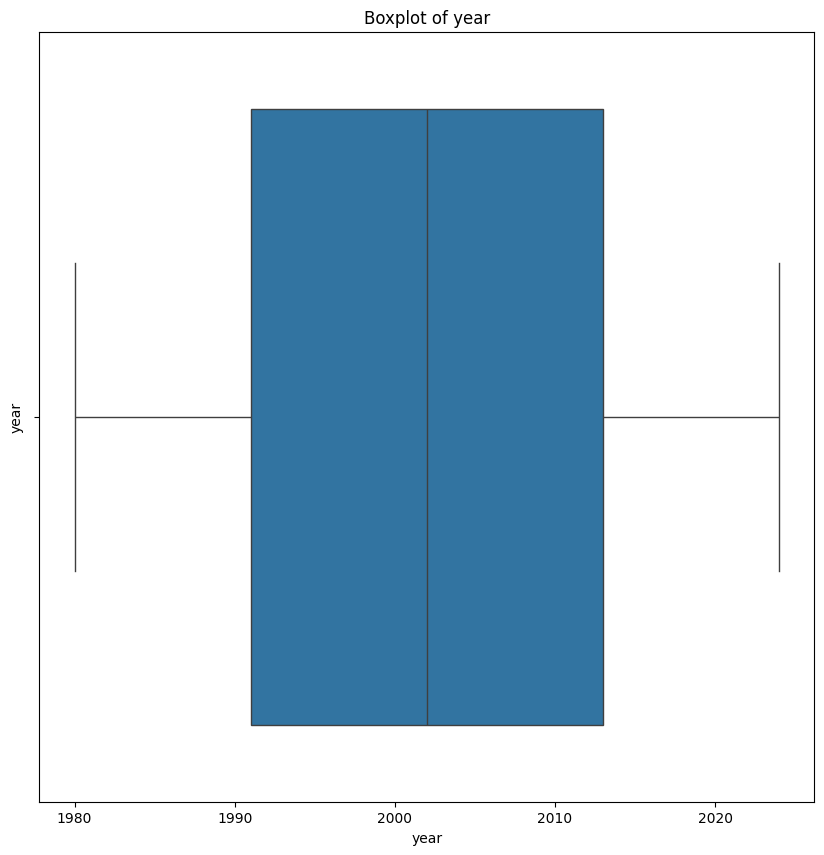

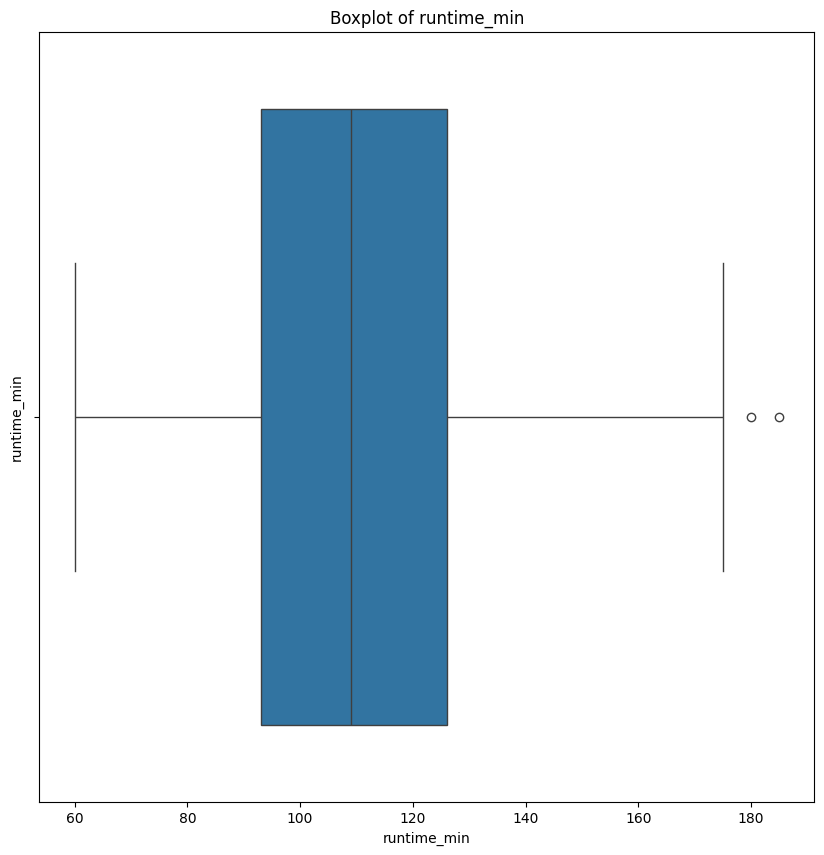

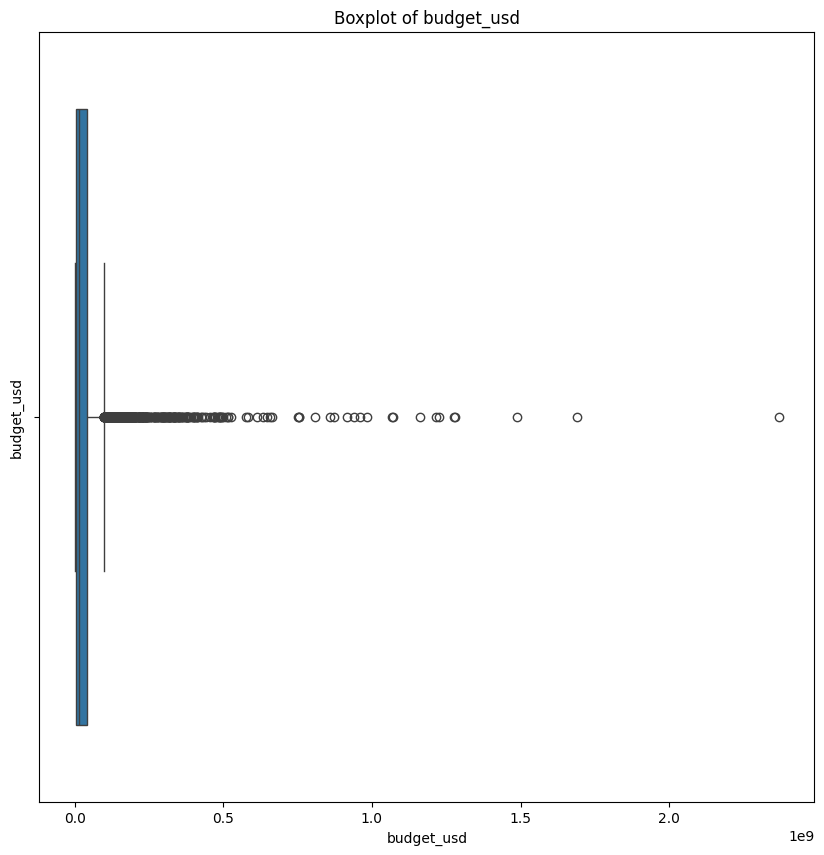

In [9]:
#Plots dataframe boxplots before outlier removal
for col in num_cols:
    plt.figure(figsize=(10, 10))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()


In [10]:
#Remove outliers by using the IQR method
df_no_outliers = df.copy()

for col in num_cols:
    Q1 = df_no_outliers[col].quantile(0.25)
    Q3 = df_no_outliers[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower_bound) & (df_no_outliers[col] <= upper_bound)]

print("Shape before outlier removal: ", df.shape)
print("Shape after outlier removal: ", df_no_outliers.shape)
print("Blockbusters kept: ", df_no_outliers['blockbuster'].value_counts()[1])

df = df_no_outliers.copy()

Shape before outlier removal:  (5000, 5)
Shape after outlier removal:  (4476, 5)
Blockbusters kept:  485


In [11]:
#Convert genre colum into dummy variables that will be used for chi-squared screening
genre_dummies = pd.get_dummies(df["genre"], prefix="genre", drop_first=True, dtype=int)

#Constructs a modeling dataframe
df = pd.concat([df, genre_dummies], axis=1)

df.drop(columns=["genre"])

,year,runtime_min,budget_usd,blockbuster,genre_Adventure,genre_Animation,genre_Comedy,genre_Documentary,genre_Drama,genre_Horror,genre_Romance,genre_Sci-Fi,genre_Thriller
0,2020,96,20892328.61,0,0,0,1,0,0,0,0,0,0
2,1995,79,8793950.08,0,0,0,0,0,0,1,0,0,0
3,1988,101,3871709.60,0,0,0,1,0,0,0,0,0,0
4,2023,75,1283538.54,0,0,0,0,1,0,0,0,0,0
5,1985,137,17573804.73,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,2021,71,25484024.19,0,0,0,1,0,0,0,0,0,0
4996,2002,75,90455850.14,0,0,0,1,0,0,0,0,0,0
4997,1998,79,790692.29,0,0,0,0,1,0,0,0,0,0
4998,2012,98,8636782.98,0,0,0,0,1,0,0,0,0,0


Step 3: Feature Engineering

A.) Feature Variance

In [12]:
#Numerical Variables
num_cols = ['year','runtime_min',	'budget_usd']

#Checks the variance of numerical features
print("Variance: ")
print(df[num_cols].var())

Variance: 
year           1.683582e+02
runtime_min    4.870020e+02
budget_usd     5.032360e+14
dtype: float64


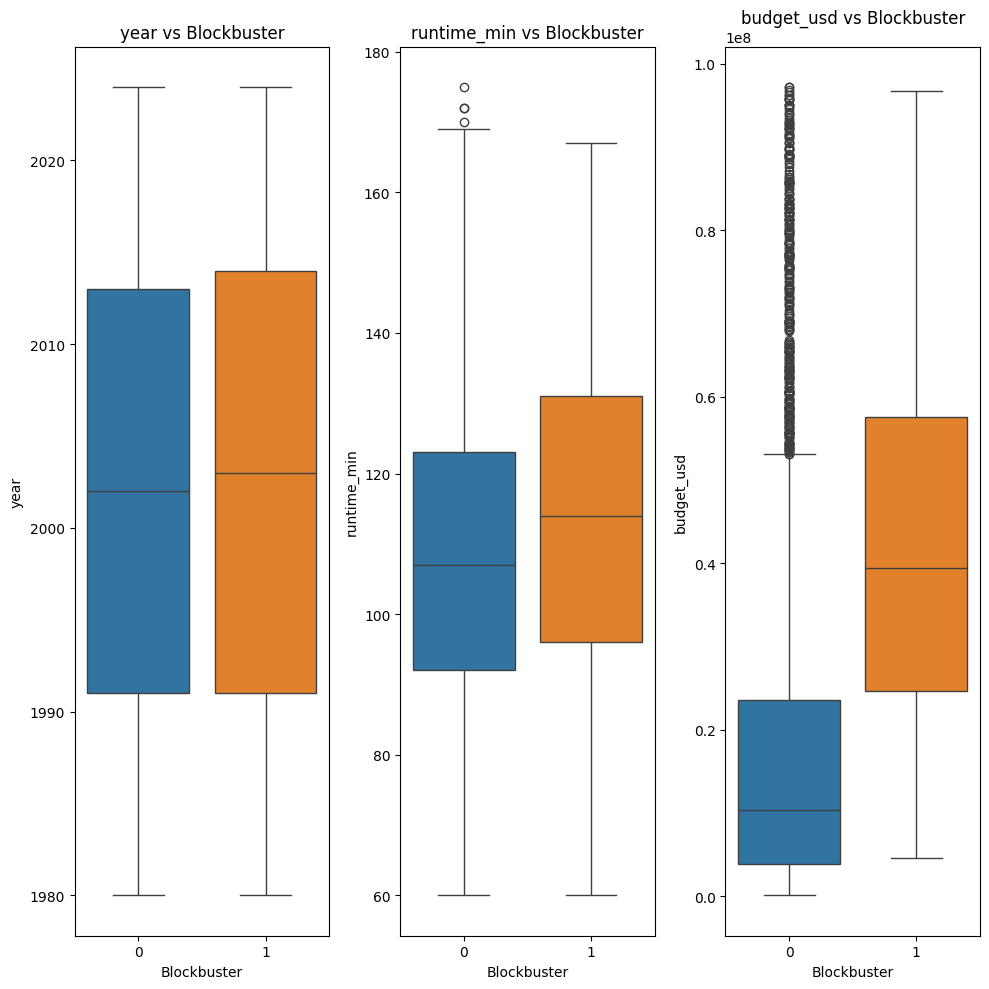

In [13]:
# Define the numerical features and target variable
features_to_plot = ['year', 'runtime_min', 'budget_usd']
target = 'blockbuster'

# Configure subplot layout grid (1 rows, 3 columns for 3 features)
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 10))
axes = axes.flatten()  # Flatten the 2D grid of axes into 1D for easy iteration

for i, col in enumerate(features_to_plot):
    sns.boxplot(x=target, y=col, data=df, ax=axes[i], hue=target, legend=False)
    axes[i].set_title(f'{col} vs {target.capitalize()}')
    axes[i].set_xlabel(target.capitalize())
    axes[i].set_ylabel(col)

# Adjust spacing and display plot
plt.tight_layout()
plt.show()

B.) Feature Correlation

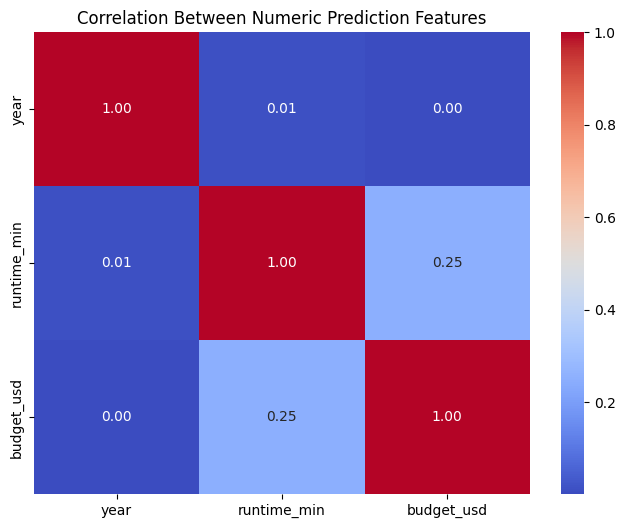

In [14]:
#Feature Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[['year', 'runtime_min', 'budget_usd']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Between Numeric Prediction Features')
plt.show()

C.) Split Data before statistical selection

In [15]:
#Define model features - dropping both 'blockbuster' and the non-encoded 'genre' string column
x = df.drop(columns=['blockbuster'])
y = df['blockbuster']

#Train Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

D.) Anova Test

In [16]:
#Anova Test
x = df[['year', 'runtime_min', 'budget_usd']]
y = df['blockbuster']

fs = SelectKBest(score_func=f_classif, k='all')
fs.fit(x,y)

np.set_printoptions(suppress = True)

print("F-Scores: ")
print(fs.scores_)

print("P-Values: ")
print(fs.pvalues_)

anova_results = pd.DataFrame({
    'Feature': x.columns,
    'F-Score': fs.scores_,
    'P-Value': fs.pvalues_
})

print("\nANOVA Results:")
print(anova_results)

#Keeps features with p-values below 0.05
selected_num_features = anova_results[anova_results['P-Value'] < 0.05]['Feature'].tolist()

print("\nSelected Features: ", selected_num_features)

#Drops features with p-values above 0.05
dropped_features = anova_results[anova_results['P-Value'] >= 0.05]['Feature'].tolist()
print("Dropped Features: ", dropped_features)

F-Scores: 
[  1.16118153  38.74396558 622.60560686]
P-Values: 
[0.28127873 0.         0.        ]

ANOVA Results:
       Feature     F-Score        P-Value
0         year    1.161182   2.812787e-01
1  runtime_min   38.743966   5.274726e-10
2   budget_usd  622.605607  8.946542e-129

Selected Features:  ['runtime_min', 'budget_usd']
Dropped Features:  ['year']


E.) Chi-Squared Test

In [17]:
#Chi-Squared test to determine genre association with target variable
genre_cols = [col for col in df.columns if col.startswith('genre_')]

chi = SelectKBest(score_func=chi2, k='all')
chi.fit(df[genre_cols], df['blockbuster'])

chi_results = pd.DataFrame({
    'Feature': genre_cols,
    'Chi-Squared Score': chi.scores_,
    'P-Value': chi.pvalues_
})

print("\nChi-Squared Results:")
print(chi_results.sort_values(by='P-Value'))

#Keeps features with p-values below 0.05
selected_genre_features = chi_results[chi_results['P-Value'] < 0.05]['Feature'].tolist()

print("\nSelected Features: ", selected_genre_features)

#Drops features with p-values above 0.05
dropped_features = chi_results[chi_results['P-Value'] >= 0.05]['Feature'].tolist()
print("Dropped Features: ", dropped_features)


Chi-Squared Results:
             Feature  Chi-Squared Score       P-Value
1    genre_Animation         108.390818  2.206777e-25
3  genre_Documentary          66.108745  4.267184e-16
7       genre_Sci-Fi          39.256713  3.715887e-10
6      genre_Romance          38.804664  4.684074e-10
0    genre_Adventure          32.749401  1.048386e-08
4        genre_Drama          30.877233  2.748776e-08
2       genre_Comedy          18.441879  1.751657e-05
8     genre_Thriller          13.773652  2.062080e-04
5       genre_Horror           0.345388  5.567354e-01

Selected Features:  ['genre_Adventure', 'genre_Animation', 'genre_Comedy', 'genre_Documentary', 'genre_Drama', 'genre_Romance', 'genre_Sci-Fi', 'genre_Thriller']
Dropped Features:  ['genre_Horror']


F.) Combine features into one dataset

In [18]:
#Combines features
selected_features = selected_num_features + selected_genre_features

x_train_selected = x_train[selected_features].copy()
x_test_selected = x_test[selected_features].copy()

print("Selected Features: ", selected_features)

print("Shape of x_train_selected: ", x_train_selected.shape)
print("Shape of x_test_selected: ", x_test_selected.shape)

Selected Features:  ['runtime_min', 'budget_usd', 'genre_Adventure', 'genre_Animation', 'genre_Comedy', 'genre_Documentary', 'genre_Drama', 'genre_Romance', 'genre_Sci-Fi', 'genre_Thriller']
Shape of x_train_selected:  (3580, 10)
Shape of x_test_selected:  (896, 10)


Step 4: Build the Prediction Model

In [19]:
#Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', min_samples_leaf=2, n_jobs=-1)
model.fit(x_train_selected, y_train)

y_pred = model.predict(x_test_selected)
y_prob = model.predict_proba(x_test_selected)[:, 1]

I selected the RandomForestClassifier for the model because it can handle classification problems, allowing the model to classify a movie as either a blockbuster or not. It also helps identify nonlinear relationships, which is relevant, as the selected features may affect the target variable in nonlinear ways.

In [20]:
#Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, x_train_selected, y_train, cv=cv, scoring='f1', n_jobs=-1)

print("Cross-Validation F1 Scores:", scores)
print("Mean F1 Score:", scores.mean())
print("Standard Deviation of F1 Scores:", scores.std())


Cross-Validation F1 Scores: [0.24827586 0.33333333 0.34899329 0.38095238 0.36809816]
Mean F1 Score: 0.3359306048908972
Standard Deviation of F1 Scores: 0.04673851806382684


I used cross-validation for the model as the data is significantly unbalanced, meaning that the F1-score cross-validation provides would allow us to receive a more accurate measure of the model's performance in comparison to a train_test_split.

In [21]:
#Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Accuracy:", round(accuracy, 4))
print("Balanced Accuracy:", round(balanced_acc, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       798
           1       0.39      0.46      0.42        98

    accuracy                           0.86       896
   macro avg       0.66      0.69      0.67       896
weighted avg       0.87      0.86      0.87       896

Accuracy: 0.8616
Balanced Accuracy: 0.6851
Precision: 0.3879
Recall: 0.4592
F1 Score: 0.4206


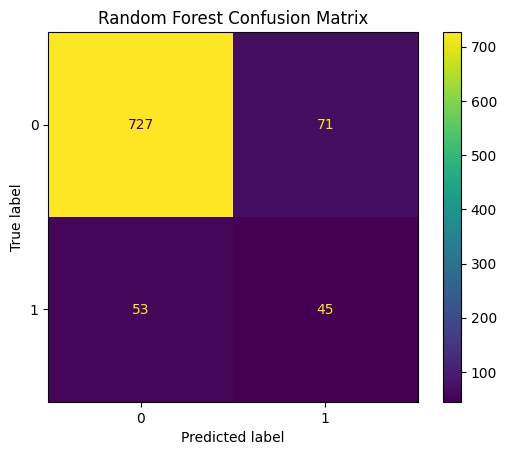

In [22]:
#Display Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
#Displays feature importance to the Random Forest Model
feature_importances = pd.DataFrame({
    'Feature': selected_features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(feature_importances)


,Feature,Importance
1,budget_usd,0.618699
0,runtime_min,0.218543
5,genre_Documentary,0.043055
7,genre_Romance,0.031038
6,genre_Drama,0.024503
3,genre_Animation,0.020549
4,genre_Comedy,0.016088
9,genre_Thriller,0.013862
2,genre_Adventure,0.006878
8,genre_Sci-Fi,0.006786


Analyze model Result:

The model achieved approximately 86% accuracy after training. It successfully identified non-blockbuster movies with an F1-score of 0.92; however, it struggled to identify blockbusters, with an F1-score of 0.42. A major reason for this difference is that the dataset contained significantly more non-blockbuster movies than blockbuster movies. This class imbalance likely caused the model to favor predicting non-blockbusters, making it more difficult to identify blockbuster movies. It also had limited prediction features because a movie's year, runtime, budget, and genre cannot fully explain a movie's guaranteed success.